# Stage 2: Inferential Statistics

## Objective

This stage asks whether the links seen in the survey sample are real or could be due to chance. It covers the tests listed in the team tracker (S2.1 to S2.6): correlations between perceptions and satisfaction (H1 to H4), satisfaction and spending (H5), pity timing and spending (H6), objective and perceived luck (H8), and group comparisons for the featured character, promotions, top-up triggers and game.

The analysis uses 510 cleaned survey responses from adult Vietnamese gacha players recruited through online communities. Recruitment was non-random, so the results describe associations in this sample and are not claimed to hold for all players. The survey is a one-time snapshot, so we write "is associated with", not "causes".

The tests are split into two families, each with its own Holm correction:

- **Core family (5 tests, tracker S2.1 to S2.3):** the four Spearman correlations H1 to H4 and the chi-square test of promotions by spending group. These are the tests reported in the main text of the report.
- **Supplementary family (12 tests):** H5, H6, H8, the featured-character test, the trigger test and the six game comparisons. These are reported as additional, exploratory results.

Sensitivity checks and post-hoc comparisons are reported separately and belong to neither family.

## 1. Load the survey data and set up helper functions

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import chi2_contingency, spearmanr
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt

ALPHA = 0.05
N_BOOT = 5000
SEED = 24521386

# Tìm CSV khi notebook chạy từ gốc repo hoặc từ Data_Analysis.
csv_path = Path("Dataset/gacha_clean.csv")
if not csv_path.is_file():
    csv_path = Path("../Dataset/gacha_clean.csv")

df = pd.read_csv(csv_path, encoding="utf-8-sig")
print(f"Dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột")

# Thư mục lưu kết quả ở gốc repo.
output_dir = csv_path.resolve().parents[1] / "outputs" / "stage2"
(output_dir / "figures").mkdir(parents=True, exist_ok=True)
(output_dir / "tables").mkdir(parents=True, exist_ok=True)

# Mọi kiểm định chính được gom vào danh sách này, sau đó Holm chạy một lần.
results = []

def add_result(hyp, variables, test, n, statistic, dof, effect_name, effect,
               p_raw, ci_low=np.nan, ci_high=np.nan):
    results.append({
        "hypothesis": hyp, "variables": variables, "test": test, "n": int(n),
        "statistic": statistic, "df": dof, "effect_name": effect_name,
        "effect": effect, "ci_low": ci_low, "ci_high": ci_high, "p_raw": p_raw,
    })

Dữ liệu: 510 dòng, 52 cột


In [2]:
rng = np.random.default_rng(SEED)

def spearman_boot(x, y, n_boot=N_BOOT):
    """Spearman rho, p-value hai phía và CI 95% bootstrap (lấy lại mẫu theo dòng)."""
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    n = len(x)
    rho, p = spearmanr(x, y)
    boots = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)
        boots[i] = spearmanr(x[idx], y[idx]).statistic
    lo, hi = np.quantile(boots, [0.025, 0.975])
    return rho, lo, hi, p, n

def jonckheere_terpstra(groups):
    """Kiểm định xu hướng Jonckheere-Terpstra (xấp xỉ chuẩn, có hiệu chỉnh đồng hạng).
    Các nhóm phải được xếp theo thứ tự tăng dần của biến nhóm."""
    groups = [np.asarray(g, float) for g in groups]
    J = 0.0
    for i in range(len(groups)):
        for j in range(i + 1, len(groups)):
            diff = groups[j][None, :] - groups[i][:, None]
            J += (diff > 0).sum() + 0.5 * (diff == 0).sum()
    n = np.array([len(g) for g in groups])
    N = n.sum()
    t = np.unique(np.concatenate(groups), return_counts=True)[1]
    mean = (N**2 - (n**2).sum()) / 4
    v1 = (N * (N - 1) * (2 * N + 5) - (n * (n - 1) * (2 * n + 5)).sum()
          - (t * (t - 1) * (2 * t + 5)).sum()) / 72
    v2 = ((n * (n - 1) * (n - 2)).sum() * (t * (t - 1) * (t - 2)).sum()) / (36 * N * (N - 1) * (N - 2))
    v3 = ((n * (n - 1)).sum() * (t * (t - 1)).sum()) / (8 * N * (N - 1))
    z = (J - mean) / np.sqrt(v1 + v2 + v3)
    return J, z, 2 * stats.norm.sf(abs(z)), N

def chi_square_table(table):
    """Chi-square độc lập + Cramér's V + ô kỳ vọng nhỏ nhất."""
    chi2, p, dof, expected = chi2_contingency(table)
    n = table.to_numpy().sum()
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    return chi2, p, dof, v, expected.min(), n

def dunn_posthoc(values, labels):
    """Dunn post-hoc sau Kruskal-Wallis (có hiệu chỉnh đồng hạng), Holm trong từng nhóm so sánh."""
    values = np.asarray(values, float)
    labels = np.asarray(labels)
    ranks = stats.rankdata(values)
    N = len(ranks)
    ties = np.unique(values, return_counts=True)[1]
    sigma2 = N * (N + 1) / 12 - (ties**3 - ties).sum() / (12 * (N - 1))
    cats = list(pd.unique(labels))
    mean_rank = {c: ranks[labels == c].mean() for c in cats}
    size = {c: (labels == c).sum() for c in cats}
    rows = []
    for i in range(len(cats)):
        for j in range(i + 1, len(cats)):
            a, b = cats[i], cats[j]
            z = (mean_rank[a] - mean_rank[b]) / np.sqrt(sigma2 * (1 / size[a] + 1 / size[b]))
            rows.append({"group_a": a, "group_b": b, "z": z, "p_raw": 2 * stats.norm.sf(abs(z))})
    out = pd.DataFrame(rows)
    out["p_holm"] = multipletests(out["p_raw"], method="holm")[1]
    return out

## 2. H1 to H4: Spearman correlations

- H1: perceived luck (`LUCK`) and satisfaction (`SAT`).
- H2: perceived fairness of the pity system (`PITY2`) and satisfaction (`SAT`).
- H3: perceived price fairness (`PRICE`) and satisfaction (`SAT`).
- H4: satisfaction (`SAT`) and intention to keep playing (`RET1`).

For each pair, H0 is that Spearman's rho is zero. We use Spearman because the scores are ordinal. The 95% CI comes from a bootstrap with 5,000 resamples and a fixed seed. `PITY2` and `RET1` replace `PITY` and `RET`, whose Cronbach's alpha was below 0.70.

In [3]:
pairs = [("H1", "LUCK", "SAT"), ("H2", "PITY2", "SAT"),
         ("H3", "PRICE", "SAT"), ("H4", "SAT", "RET1")]

for hyp, x_col, y_col in pairs:
    x, y = df[[x_col, y_col]].dropna().to_numpy().T
    rho, lo, hi, p, n = spearman_boot(x, y)
    add_result(hyp, f"{x_col} ~ {y_col}", "Spearman", n, rho, np.nan,
               "Spearman's rho", rho, p, lo, hi)

pd.DataFrame(results).round({"effect": 4, "ci_low": 4, "ci_high": 4})[
    ["hypothesis", "variables", "n", "effect", "ci_low", "ci_high", "p_raw"]]

,hypothesis,variables,n,effect,ci_low,ci_high,p_raw
0,H1,LUCK ~ SAT,510,0.3076,0.2194,0.3925,1.226760e-12
1,H2,PITY2 ~ SAT,510,0.4432,0.3657,0.5153,5.900252e-26
2,H3,PRICE ~ SAT,510,0.4537,0.3820,0.5235,2.905283e-27
3,H4,SAT ~ RET1,510,0.5043,0.4342,0.5698,2.988914e-34


## 3. H5: satisfaction and monthly spending

We test whether satisfaction (`SAT`) rises with the monthly spending group (`SPEND_MONTH4`: 0, 1, 2, 3). We use the four spending groups (`SPEND_MONTH4`) so that H5 matches the groups used in Stages 3 and 4. The top three of the six original bands (26, 10 and 15 respondents) are merged into one group of 51 respondents. No original band has fewer than 10 respondents, so section 8.4 repeats H5 with the six original levels as a sensitivity check.

- Spearman: H0 is that rho between `SAT` and `SPEND_MONTH4` is zero.
- Jonckheere-Terpstra: H0 is that `SAT` has the same distribution in all spending groups; the alternative is an ordered trend across groups. We report Z and r = Z / sqrt(N).

In [4]:
h5 = df[["SAT", "SPEND_MONTH4"]].dropna()

# Mô tả SAT theo nhóm chi để nhìn xu hướng trước khi kiểm định.
print(h5.groupby("SPEND_MONTH4")["SAT"].agg(["count", "mean", "median"]).round(3))

rho, lo, hi, p, n = spearman_boot(h5["SAT"], h5["SPEND_MONTH4"])
add_result("H5", "SAT ~ SPEND_MONTH4", "Spearman", n, rho, np.nan,
           "Spearman's rho", rho, p, lo, hi)

groups = [h5.loc[h5["SPEND_MONTH4"] == k, "SAT"].to_numpy() for k in [0, 1, 2, 3]]
J, z, p_jt, n_jt = jonckheere_terpstra(groups)
add_result("H5", "SAT across SPEND_MONTH4 (trend)", "Jonckheere-Terpstra", n_jt, z, np.nan,
           "r = Z/sqrt(N)", z / np.sqrt(n_jt), p_jt)

print(f"\nSpearman rho = {rho:.4f} [{lo:.4f}, {hi:.4f}], p = {p:.3g}")
print(f"Jonckheere-Terpstra: J = {J:.1f}, Z = {z:.3f}, p = {p_jt:.3g}")

              count   mean  median
SPEND_MONTH4                      
0.0             218  4.078   4.333
1.0             110  4.045   4.333
2.0             131  4.155   4.333
3.0              51  4.163   4.000



Spearman rho = 0.0196 [-0.0661, 0.1064], p = 0.659
Jonckheere-Terpstra: J = 45984.0, Z = 0.450, p = 0.653


## 4. H6: being near soft pity and spending group

Among respondents who answered the pity question about their top-ups (`NEAR_PITY` is Yes or No), we test whether being near soft pity when topping up is associated with the monthly spending group. The 179 respondents who answered "I didn't top up" are excluded (154 have never spent and 25 have spent before), which leaves 331 respondents. H0 is that the two variables are independent. We check expected counts and would use Fisher's test if a cell fell below 5.

In [5]:
h6 = df[df["NEAR_PITY"].isin(["Yes", "No"])]
obs_h6 = pd.crosstab(h6["NEAR_PITY"], h6["SPEND_MONTH4"])
display(obs_h6)

chi2, p, dof, v, min_exp, n = chi_square_table(obs_h6)
print(f"Minimum expected count: {min_exp:.2f}" + ("" if min_exp >= 5 else "  (below 5: use Fisher)"))
print(f"Chi-square({dof}) = {chi2:.4f}, p = {p:.3g}, n = {n}, Cramér's V = {v:.4f}")
add_result("H6", "NEAR_PITY x SPEND_MONTH4", "Chi-square", n, chi2, dof, "Cramér's V", v, p)

SPEND_MONTH4,0.0,1.0,2.0,3.0
NEAR_PITY,,,,
No,28,65,76,30
Yes,11,45,55,21


Minimum expected count: 15.55
Chi-square(3) = 2.5435, p = 0.467, n = 331, Cramér's V = 0.0877


## 5. H8: objective and perceived luck

`LUCK_OBJ` is how many of the last five wanted limited characters the respondent obtained (0 to 5). We test whether this objective outcome is associated with perceived luck (`LUCK`). H0 is that Spearman's rho is zero.

In [6]:
x, y = df[["LUCK_OBJ", "LUCK"]].dropna().to_numpy().T
rho, lo, hi, p, n = spearman_boot(x, y)
add_result("H8", "LUCK_OBJ ~ LUCK", "Spearman", n, rho, np.nan,
           "Spearman's rho", rho, p, lo, hi)
print(f"n = {n}, rho = {rho:.4f} [{lo:.4f}, {hi:.4f}], p = {p:.3g}")

n = 510, rho = 0.1976 [0.1119, 0.2793], p = 6.94e-06


## 6. Additional tests: featured character, promotions, trigger and game

**6.1 Getting the featured 5-star character and satisfaction (Mann-Whitney).** Respondents who got the featured character (through the 50/50 or the guarantee) are compared with those who did not. H0 is that `SAT` has the same distribution in both groups. The effect size is the rank-biserial correlation (positive means the "got it" group is more satisfied).

In [7]:
won = df["WON_FEATURED"].isin(["Won 50/50", "Guarantee"])
sat_yes = df.loc[won, "SAT"].to_numpy()
sat_no = df.loc[~won, "SAT"].to_numpy()
print(f"Got featured: n = {len(sat_yes)}, mean SAT = {sat_yes.mean():.3f}")
print(f"Did not:      n = {len(sat_no)}, mean SAT = {sat_no.mean():.3f}")

u, p = stats.mannwhitneyu(sat_yes, sat_no, alternative="two-sided")
rank_biserial = 2 * u / (len(sat_yes) * len(sat_no)) - 1
add_result("WON_FEATURED", "WON_FEATURED (yes/no) x SAT", "Mann-Whitney U",
           len(sat_yes) + len(sat_no), u, np.nan, "rank-biserial r", rank_biserial, p)
print(f"U = {u:.1f}, p = {p:.3g}, rank-biserial r = {rank_biserial:.4f}")

Got featured: n = 472, mean SAT = 4.134
Did not:      n = 38, mean SAT = 3.667
U = 11492.0, p = 0.00339, rank-biserial r = 0.2814


**6.2 Promotions and monthly spending group (chi-square).** H0 is that `PROMO` (spends more during promotion events) and `SPEND_MONTH4` are independent.

In [8]:
observed = pd.crosstab(df["PROMO"], df["SPEND_MONTH4"])
display(observed)

chi2, p, dof, v, min_exp, n = chi_square_table(observed)
print(f"Minimum expected count: {min_exp:.2f}" + ("" if min_exp >= 5 else "  (below 5: use Fisher)"))
print(f"Chi-square({dof}) = {chi2:.4f}, p = {p:.3g}, n = {n}, Cramér's V = {v:.4f}")
add_result("PROMO", "PROMO x SPEND_MONTH4", "Chi-square", n, chi2, dof, "Cramér's V", v, p)

SPEND_MONTH4,0.0,1.0,2.0,3.0
PROMO,,,,
No,200,77,72,6
Yes,18,33,59,45


Minimum expected count: 15.50
Chi-square(3) = 144.4402, p = 4.17e-31, n = 510, Cramér's V = 0.5322


**6.3 Top-up trigger and monthly spending group (chi-square).** `TRIGGER3` groups the six answers into character-driven, promo-driven and other. We keep respondents who have ever spent (`PAYER = 1`): the "I don't spend" answer would otherwise be tied to zero spending by definition. Among these 356 respondents, 64 report zero monthly spending (they spent in the past). H0 is that trigger group and `SPEND_MONTH4` are independent.

In [9]:
trig = df[(df["PAYER"] == 1) & (df["TRIGGER3"] != "Non-spender")]
obs_trig = pd.crosstab(trig["TRIGGER3"], trig["SPEND_MONTH4"])
display(obs_trig)

chi2, p, dof, v, min_exp, n = chi_square_table(obs_trig)
print(f"Minimum expected count: {min_exp:.2f}" + ("" if min_exp >= 5 else "  (below 5: use Fisher)"))
print(f"Chi-square({dof}) = {chi2:.4f}, p = {p:.3g}, n = {n}, Cramér's V = {v:.4f}")
add_result("TRIGGER", "TRIGGER3 x SPEND_MONTH4", "Chi-square", n, chi2, dof, "Cramér's V", v, p)

SPEND_MONTH4,0.0,1.0,2.0,3.0
TRIGGER3,,,,
Character-driven,34,65,71,38
Other,14,21,20,2
Promo-driven,16,24,40,11


Minimum expected count: 8.17
Chi-square(6) = 11.8981, p = 0.0643, n = 356, Cramér's V = 0.1293


**6.4 Game and the six scales (Kruskal-Wallis).** We compare `LUCK`, `PITY2`, `PRICE`, `SAT`, `INT` and `RET1` across the four named games (Genshin Impact, Honkai: Star Rail, Zenless Zone Zero, Wuthering Waves). The "Other" group (33 respondents) is left out because it mixes different games. H0 is that the scale has the same distribution in all four games. The effect size is epsilon-squared, H / (N - 1).

In [10]:
scales = ["LUCK", "PITY2", "PRICE", "SAT", "INT", "RET1"]
games = df[df["GAME"] != "Other"]
print(games["GAME"].value_counts().to_string(), "\n")

for scale in scales:
    samples = [g[scale].to_numpy() for _, g in games.groupby("GAME")]
    h, p = stats.kruskal(*samples)
    n = len(games)
    add_result("GAME", f"GAME x {scale}", "Kruskal-Wallis", n, h, len(samples) - 1,
               "epsilon-squared", h / (n - 1), p)
    print(f"{scale:6s} H = {h:6.2f}, p = {p:.3g}, epsilon^2 = {h / (n - 1):.4f}")

GAME
ZZZ        219
Genshin    151
HSR         81
WuWa        26 

LUCK   H =   3.31, p = 0.346, epsilon^2 = 0.0070
PITY2  H =   2.92, p = 0.404, epsilon^2 = 0.0061
PRICE  H =  19.50, p = 0.000216, epsilon^2 = 0.0410
SAT    H =  26.46, p = 7.63e-06, epsilon^2 = 0.0556
INT    H =   9.41, p = 0.0243, epsilon^2 = 0.0198
RET1   H =  10.03, p = 0.0183, epsilon^2 = 0.0211


## 7. Holm correction and results summary

Holm correction is applied separately within the core family (5 tests) and within the supplementary family (12 tests). We judge significance at 0.05 using the adjusted p-values.

In [11]:
summary = pd.DataFrame(results)

# Nhóm lõi (tracker S2.1 đến S2.3) và nhóm bổ sung; Holm chạy riêng trong từng nhóm.
CORE = {"H1", "H2", "H3", "H4", "PROMO"}
summary["family"] = np.where(summary["hypothesis"].isin(CORE), "core", "supplementary")
summary["p_holm"] = np.nan
summary["reject_h0"] = False
for fam, idx in summary.groupby("family").groups.items():
    rej, adj, _, _ = multipletests(summary.loc[idx, "p_raw"], alpha=ALPHA, method="holm")
    summary.loc[idx, "p_holm"] = adj
    summary.loc[idx, "reject_h0"] = rej
    print(f"Nhóm {fam}: {len(idx)} kiểm định, {int(rej.sum())} có ý nghĩa sau Holm")

summary = summary.sort_values("family", key=lambda c: c.map({"core": 0, "supplementary": 1}),
                              kind="stable").reset_index(drop=True)

summary.to_csv(output_dir / "tables" / "stage2_results.csv", index=False)

shown = summary.copy()
for col in ["p_raw", "p_holm"]:
    shown[col] = shown[col].map(lambda v: f"{v:.2e}")
display(shown[["family", "hypothesis", "variables", "test", "n", "statistic", "df",
               "effect_name", "effect", "ci_low", "ci_high",
               "p_raw", "p_holm", "reject_h0"]].round(3))

Nhóm core: 5 kiểm định, 5 có ý nghĩa sau Holm
Nhóm supplementary: 12 kiểm định, 4 có ý nghĩa sau Holm


,family,hypothesis,variables,test,n,statistic,df,effect_name,effect,ci_low,ci_high,p_raw,p_holm,reject_h0
0,core,H1,LUCK ~ SAT,Spearman,510,0.308,NaN,Spearman's rho,0.308,0.219,0.393,1.23e-12,1.23e-12,True
1,core,H2,PITY2 ~ SAT,Spearman,510,0.443,NaN,Spearman's rho,0.443,0.366,0.515,5.90e-26,1.18e-25,True
2,core,H3,PRICE ~ SAT,Spearman,510,0.454,NaN,Spearman's rho,0.454,0.382,0.524,2.91e-27,8.72e-27,True
3,core,H4,SAT ~ RET1,Spearman,510,0.504,NaN,Spearman's rho,0.504,0.434,0.570,2.99e-34,1.49e-33,True
4,core,PROMO,PROMO x SPEND_MONTH4,Chi-square,510,144.440,3.0,Cramér's V,0.532,NaN,NaN,4.17e-31,1.67e-30,True
5,supplementary,H5,SAT ~ SPEND_MONTH4,Spearman,510,0.020,NaN,Spearman's rho,0.020,-0.066,0.106,6.59e-01,1.00e+00,False
6,supplementary,H5,SAT across SPEND_MONTH4 (trend),Jonckheere-Terpstra,510,0.450,NaN,r = Z/sqrt(N),0.020,NaN,NaN,6.53e-01,1.00e+00,False
7,supplementary,H6,NEAR_PITY x SPEND_MONTH4,Chi-square,331,2.544,3.0,Cramér's V,0.088,NaN,NaN,4.67e-01,1.00e+00,False
8,supplementary,H8,LUCK_OBJ ~ LUCK,Spearman,510,0.198,NaN,Spearman's rho,0.198,0.112,0.279,6.94e-06,8.32e-05,True
9,supplementary,WON_FEATURED,WON_FEATURED (yes/no) x SAT,Mann-Whitney U,510,11492.000,NaN,rank-biserial r,0.281,NaN,NaN,3.39e-03,3.05e-02,True


## 8. Post-hoc comparisons and sensitivity checks

**8.1 Dunn post-hoc test.** For each scale where the Kruskal-Wallis test remained significant after Holm, we compare games pairwise with Dunn's test (tie-corrected), with Holm applied within each scale. These comparisons are outside the main family.

In [12]:
sig_scales = [row["variables"].split(" x ")[1]
              for _, row in summary.iterrows()
              if row["test"] == "Kruskal-Wallis" and row["reject_h0"]]
print("Thang đo có khác biệt giữa các game:", sig_scales)

dunn_all = []
for scale in sig_scales:
    out = dunn_posthoc(games[scale], games["GAME"])
    out.insert(0, "scale", scale)
    dunn_all.append(out)
    print(f"\n{scale}: mean by game")
    print(games.groupby("GAME")[scale].mean().round(2).to_string())
    display(out.round({"z": 3, "p_raw": 5, "p_holm": 5}))

if dunn_all:
    pd.concat(dunn_all).to_csv(output_dir / "tables" / "stage2_dunn_posthoc.csv", index=False)

Thang đo có khác biệt giữa các game: ['PRICE', 'SAT']

PRICE: mean by game
GAME
Genshin    2.87
HSR        3.06
WuWa       3.19
ZZZ        3.31


,scale,group_a,group_b,z,p_raw,p_holm
0,PRICE,WuWa,HSR,0.505,0.61383,0.79987
1,PRICE,WuWa,Genshin,1.282,0.19997,0.79987
2,PRICE,WuWa,ZZZ,-0.890,0.37325,0.79987
3,PRICE,HSR,Genshin,1.150,0.25013,0.79987
4,PRICE,HSR,ZZZ,-2.295,0.02174,0.10869
5,PRICE,Genshin,ZZZ,-4.319,0.00002,0.00009



SAT: mean by game
GAME
Genshin    3.99
HSR        3.82
WuWa       4.03
ZZZ        4.31


,scale,group_a,group_b,z,p_raw,p_holm
0,SAT,WuWa,HSR,1.365,0.17210,0.68841
1,SAT,WuWa,Genshin,0.576,0.56431,0.68841
2,SAT,WuWa,ZZZ,-1.351,0.17662,0.68841
3,SAT,HSR,Genshin,-1.346,0.17828,0.68841
4,SAT,HSR,ZZZ,-4.522,0.00001,0.00004
5,SAT,Genshin,ZZZ,-3.807,0.00014,0.00070


**8.2 Sensitivity: satisfaction from Q22 and Q23 only (`SAT2`).** We repeat H1 to H4 with `SAT2` in place of `SAT` (the item Q24 is dropped). These results are not part of the Holm family.

In [13]:
sens_rows = []
for hyp, x_col, y_col in pairs:
    x_s = "SAT2" if x_col == "SAT" else x_col
    y_s = "SAT2" if y_col == "SAT" else y_col
    x, y = df[[x_s, y_s]].dropna().to_numpy().T
    rho, lo, hi, p, n = spearman_boot(x, y)
    base = summary.loc[summary["hypothesis"] == hyp, "effect"].iloc[0]
    sens_rows.append({"hypothesis": hyp, "variables": f"{x_s} ~ {y_s}", "n": n,
                      "rho_SAT": base, "rho_SAT2": rho, "ci_low": lo, "ci_high": hi, "p_raw": p})

sens = pd.DataFrame(sens_rows)
sens.to_csv(output_dir / "tables" / "stage2_sensitivity_sat2.csv", index=False)
display(sens.round({"rho_SAT": 3, "rho_SAT2": 3, "ci_low": 3, "ci_high": 3}))

,hypothesis,variables,n,rho_SAT,rho_SAT2,ci_low,ci_high,p_raw
0,H1,LUCK ~ SAT2,510,0.308,0.262,0.175,0.348,1.815473e-09
1,H2,PITY2 ~ SAT2,510,0.443,0.413,0.336,0.487,2.223860e-22
2,H3,PRICE ~ SAT2,510,0.454,0.431,0.355,0.505,1.755225e-24
3,H4,SAT2 ~ RET1,510,0.504,0.501,0.425,0.569,8.616078e-34


**8.3 Sensitivity: promotions among current payers only.** We repeat the PROMO test for the 292 respondents who report positive monthly spending (`SPEND_MONTH4` of 1, 2 or 3), to see whether the association remains when the zero-spending group is removed. That group is not simply unable to respond to promotions (18 of its 218 members answered Yes), but most of its members do not spend monthly, so it may drive part of the overall association.

In [14]:
payers = df[df["SPEND_MONTH4"] > 0]
obs_payers = pd.crosstab(payers["PROMO"], payers["SPEND_MONTH4"])
display(obs_payers)

chi2_p, p_payers, dof_p, v_p, min_exp_p, n_p = chi_square_table(obs_payers)
print(f"Minimum expected count: {min_exp_p:.2f}")
print(f"Chi-square({dof_p}) = {chi2_p:.4f}, p = {p_payers:.3g}, n = {n_p}, Cramér's V = {v_p:.4f}")

SPEND_MONTH4,1.0,2.0,3.0
PROMO,,,
No,77,72,6
Yes,33,59,45


Minimum expected count: 23.93
Chi-square(2) = 47.7856, p = 4.2e-11, n = 292, Cramér's V = 0.4045


**8.4 Sensitivity: H5 with the six original spending levels.** We repeat both H5 tests with the six levels of the monthly spending question (`SPEND_MONTH`, codes 0 to 5) instead of the four merged groups.

In [15]:
h5_six = df[["SAT", "SPEND_MONTH"]].dropna()
print(h5_six.groupby("SPEND_MONTH")["SAT"].agg(["count", "mean"]).round(3))

rho6, lo6, hi6, p6, n6 = spearman_boot(h5_six["SAT"], h5_six["SPEND_MONTH"])
groups6 = [h5_six.loc[h5_six["SPEND_MONTH"] == k, "SAT"].to_numpy() for k in range(6)]
J6, z6, p_jt6, n_jt6 = jonckheere_terpstra(groups6)

print(f"\nSpearman rho = {rho6:.4f} [{lo6:.4f}, {hi6:.4f}], p = {p6:.3g}")
print(f"Jonckheere-Terpstra: Z = {z6:.3f}, p = {p_jt6:.3g}")

pd.DataFrame([
    {"test": "Spearman", "statistic": rho6, "ci_low": lo6, "ci_high": hi6, "p_raw": p6, "n": n6},
    {"test": "Jonckheere-Terpstra", "statistic": z6, "ci_low": np.nan, "ci_high": np.nan, "p_raw": p_jt6, "n": n_jt6},
]).to_csv(output_dir / "tables" / "stage2_sensitivity_h5_six_levels.csv", index=False)

             count   mean
SPEND_MONTH              
0.0            218  4.078
1.0            110  4.045
2.0            131  4.155
3.0             26  4.167
4.0             10  3.800
5.0             15  4.400



Spearman rho = 0.0205 [-0.0703, 0.1041], p = 0.645
Jonckheere-Terpstra: Z = 0.475, p = 0.635


## 9. Figures

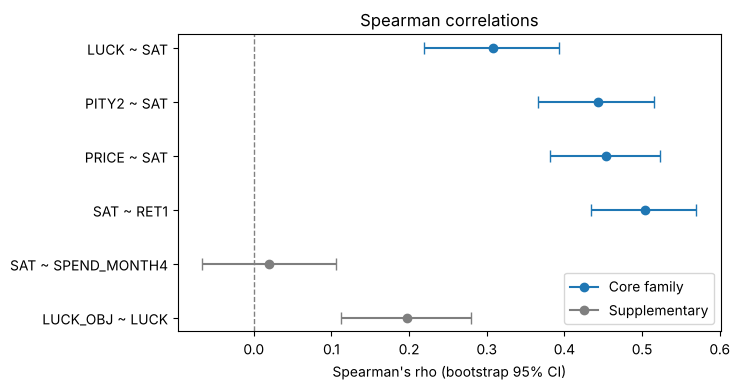

In [16]:
# Hình 1: forest plot của các hệ số Spearman (CI 95% bootstrap); nhóm lõi màu xanh, nhóm bổ sung màu xám.
from matplotlib.lines import Line2D

sp_rows = summary[summary["test"] == "Spearman"].iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7.5, 4))
for i, row in sp_rows.iterrows():
    color = "tab:blue" if row["family"] == "core" else "tab:grey"
    ax.errorbar(row["effect"], i,
                xerr=[[row["effect"] - row["ci_low"]], [row["ci_high"] - row["effect"]]],
                fmt="o", capsize=4, color=color)
ax.set_yticks(range(len(sp_rows)))
ax.set_yticklabels(sp_rows["variables"])
ax.axvline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Spearman's rho (bootstrap 95% CI)")
ax.set_title("Spearman correlations")
ax.legend(handles=[Line2D([0], [0], marker="o", color="tab:blue", label="Core family"),
                   Line2D([0], [0], marker="o", color="tab:grey", label="Supplementary")],
          loc="lower right")
fig.tight_layout()
fig.savefig(output_dir / "figures" / "spearman_forest.png", dpi=300)
plt.show()

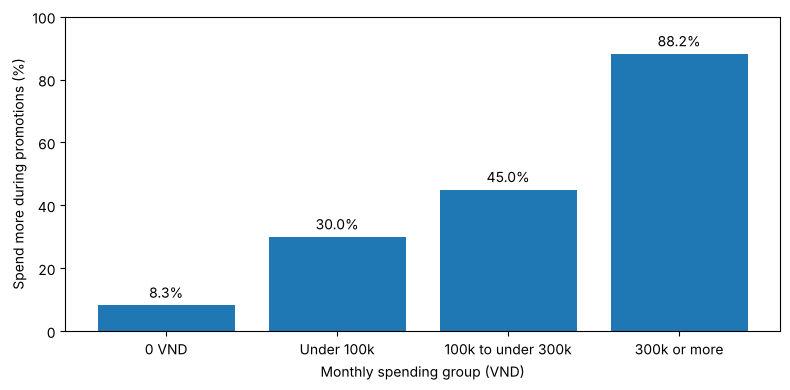

In [17]:
# Hình 2: tỷ lệ người nói nạp nhiều hơn khi có khuyến mãi theo nhóm chi tiêu tháng.
spending_groups = [0, 1, 2, 3]
yes_counts = observed.loc["Yes", spending_groups]
group_totals = observed[spending_groups].sum(axis=0)
yes_percent = 100 * yes_counts / group_totals
labels = ["0 VND", "Under 100k", "100k to under 300k", "300k or more"]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, yes_percent.to_numpy())
ax.bar_label(bars, labels=[f"{value:.1f}%" for value in yes_percent], padding=3)
ax.set_ylim(0, 100)
ax.set_xlabel("Monthly spending group (VND)")
ax.set_ylabel("Spend more during promotions (%)")
fig.tight_layout()
fig.savefig(output_dir / "figures" / "promotion_by_spending_group.png", dpi=300)
plt.show()

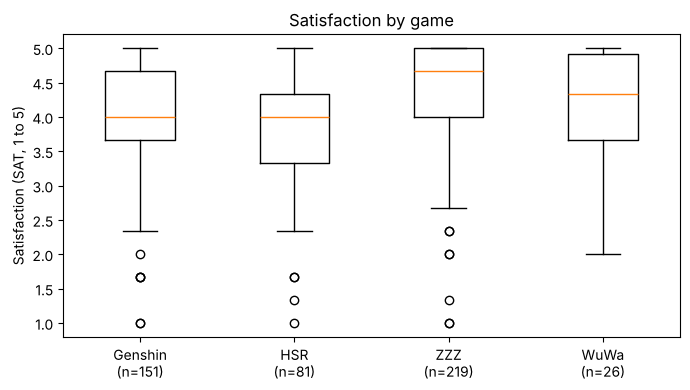

In [18]:
# Hình 3: SAT theo game (4 game có tên), minh họa cho Kruskal-Wallis.
order = ["Genshin", "HSR", "ZZZ", "WuWa"]
data = [games.loc[games["GAME"] == g, "SAT"].to_numpy() for g in order]
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(data, tick_labels=[f"{g}\n(n={len(d)})" for g, d in zip(order, data)])
ax.set_ylabel("Satisfaction (SAT, 1 to 5)")
ax.set_title("Satisfaction by game")
fig.tight_layout()
fig.savefig(output_dir / "figures" / "sat_by_game.png", dpi=300)
plt.show()

## 10. Interpretation

All five core tests remain significant after Holm correction within the core family. Among the 12 supplementary tests, four remain significant after Holm correction within that family. We treat non-significant results as "no evidence found in this sample", not as proof that there is no association.

### Core results

**Perceptions and satisfaction (H1 to H4).** Perceived luck, perceived fairness of the pity system and perceived price fairness were each positively associated with satisfaction (Spearman rho = 0.308, 0.443 and 0.454). Satisfaction was in turn positively associated with the intention to keep playing (rho = 0.504, 95% CI [0.434, 0.570]). All four had adjusted p < 0.001. Replacing `SAT` with `SAT2` (Q22 and Q23 only) gave the same pattern (rho = 0.262, 0.413, 0.431 and 0.501).

**Promotions and spending.** Spending more during promotions was strongly associated with the monthly spending group (chi-square(3) = 144.44, Cramér's V = 0.532, adjusted p < 0.001). The share reporting higher spending during promotions rose from 8.3% in the zero-spending group to 88.2% in the group spending at least 300,000 VND per month. Among the 292 respondents with positive monthly spending, the association remained (chi-square(2) = 47.79, Cramér's V = 0.405), so it does not depend only on the zero-spending group.

### Supplementary results (exploratory)

**Satisfaction and spending (H5).** We found no evidence of a trend of satisfaction across the monthly spending groups in this sample. Spearman's rho was 0.020 (95% CI [-0.066, 0.106]) and the Jonckheere-Terpstra test gave Z = 0.45; both had an adjusted p of 1.0. Mean satisfaction was about 4.1 in every group (4.08, 4.05, 4.16 and 4.16 from the lowest to the highest spending group). Using the six original spending levels instead of the four groups gave the same result (section 8.4).

**Near soft pity (H6).** We found no evidence that being near soft pity when topping up is associated with the monthly spending group (chi-square(3) = 2.54, Cramér's V = 0.088, adjusted p = 1.0; n = 331 respondents who answered Yes or No).

**Objective and perceived luck (H8).** The number of wanted limited characters obtained was weakly but positively associated with perceived luck (rho = 0.198, 95% CI [0.112, 0.279], adjusted p < 0.001).

**Featured character and satisfaction.** Respondents who got the featured character reported higher satisfaction than those who did not (mean 4.13 versus 3.67; rank-biserial r = 0.28, adjusted p = 0.030). The group that did not get the character is small (38 respondents), so this result is less precise.

**Top-up trigger.** We found insufficient evidence that the trigger group (character-driven, promo-driven, other) is associated with the spending group (Cramér's V = 0.129, raw p = 0.064, adjusted p = 0.386). This test covers 356 respondents who have ever spent, 64 of whom report zero monthly spending.

**Game.** Among the four named games (n = 477), satisfaction and price fairness differed (adjusted p < 0.001 and p = 0.002; epsilon-squared = 0.056 and 0.041, small effects). Dunn's tests are rank-based. They show that Zenless Zone Zero players ranked higher than Genshin Impact and Honkai: Star Rail players on satisfaction, and higher than Genshin Impact players on price fairness. For description, the mean satisfaction scores were 4.31, 3.99 and 3.82, and the mean price-fairness scores were 3.31 and 2.87. We found insufficient evidence of differences across games for luck, pity fairness, spending intention and intention to keep playing (epsilon-squared up to 0.0211).

**Answer to the stage question.** Perceptions of luck, pity and price are associated with satisfaction, and satisfaction is associated with the intention to keep playing. Spending more during promotions is strongly associated with the monthly spending level. In the exploratory tests, we found no evidence that satisfaction rises with monthly spending. These results describe associations in a non-random, one-time survey of adult Vietnamese players recruited online. They do not show causes.